In [13]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, List, Sequence, Annotated

creat the state

In [14]:
class StagiaireState(TypedDict):
    name: str
    gratification: float
    age:int
    decision:Literal["std_stage", "urgent_stage"]
    result:str

In [15]:
def analyze_stagiaire(state:StagiaireState)->StagiaireState:
    age=state['age']
    gratification=state['gratification']
    if age<=30 and gratification<=4000:
        state['decision']="std_stage"
    else:
        state['decision']="urgent_stage"
    print(f"le dossier de stage de {state['name']} a ete analyse")    
    return state          

In [16]:
def standard_stage_process(state:StagiaireState):
    state['result']=f"le dossier de stage de {state['name']} a ete traite de maniere standard"
    print("*"*80)
    print(f"le dossier de stage de {state['name']} a ete traite de maniere standard")
    print("*"*80)
    return state


In [17]:
def urgent_stage_process(state:StagiaireState):
    state['result']=f"le dossier de stage de {state['name']} a ete traite de maniere urgente"
    print("="*80)
    print(f"le dossier de stage de {state['name']} a ete traite de maniere urgente")
    print("="*80)
    return state

In [18]:
def router(state:StagiaireState):
    return state['decision']

In [19]:
workflow=StateGraph(StagiaireState)
workflow.add_node("analyze_node", analyze_stagiaire)
workflow.add_node("standard_stage_node",standard_stage_process)
workflow.add_node("urgent_stage_node",urgent_stage_process)
workflow.add_edge(START,"analyze_node")
workflow.add_conditional_edges(
    "analyze_node",
    router,
    {
        "std_stage":"standard_stage_node",
        "urgent_stage":"urgent_stage_node"
    }
)
workflow.add_edge("standard_stage_node",END)
workflow.add_edge("urgent_stage_node",END)

graph=workflow.compile()

In [20]:
from IPython.display import Image

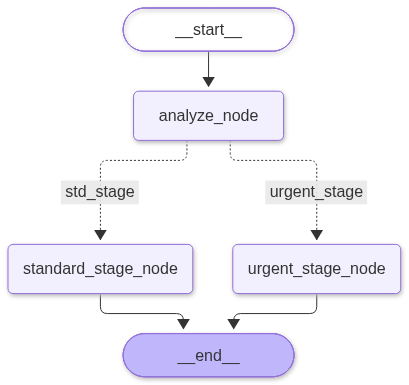

In [21]:
display(Image(graph.get_graph().draw_mermaid_png()))

le test:

In [22]:
result=graph.invoke({
    "name":"Rabab Ennaciri", "age":23, "gratification":3000
})

le dossier de stage de Rabab Ennaciri a ete analyse
********************************************************************************
le dossier de stage de Rabab Ennaciri a ete traite de maniere standard
********************************************************************************


Create agent

agent_tool

In [23]:
from langchain.tools import tool
from langchain.messages import SystemMessage, AIMessage, ToolMessage
from langchain_core.messages import BaseMessage, AnyMessage
from langgraph.graph import add_messages
from langchain_groq import ChatGroq
from langgraph.prebuilt import ToolNode

In [24]:
@tool
def somme(a:int, b:int):
    """Add two integers a and b 
    """
    print(f"Adding {a} to {b}")
    return a+b

@tool
def produit(a:int, b:int):
    """Multiply two integers a and b 
    """
    print(f"Multiplying {a} by {b}")
    return a*b

@tool
def qotient(a:int, b:int):
    """Dividing two integers a and b 
    """
    print(f"Dividing {a} by {b}")
    return a/b

tools=[somme, produit, qotient]

In [25]:
class AgentState(TypedDict):
    messages:Annotated[Sequence[BaseMessage], add_messages]

In [26]:
import os, getpass
if "GROQ_API_KEY" not in os.environ:
    os.environ["GROQ_API_KEY"]=getpass.getpass("GROQ_API_KEY: ")
llm=ChatGroq(model="openai/gpt-oss-120b",temperature=0)
llm_with_tools=llm.bind_tools(tools=tools)    

In [27]:
def assistant(state:AgentState)->AgentState:
    response=llm_with_tools.invoke(state['messages'])
    print("#"*40)
    print("LLM invoked")
    return {"messages":[response]}

In [28]:
def should_continue(state:AgentState):
    last_message=state['messages'][-1]
    if not last_message.tool_calls:
        return "end"
    else:
        return "continue"

In [29]:
workflow=StateGraph(AgentState)
workflow.add_node("assistant",assistant)
workflow.add_node("tools",ToolNode(tools=tools))
workflow.add_edge(START,"assistant")
workflow.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "end": END,
        "continue":"tools"
    }
)
workflow.add_edge("tools","assistant")
graph=workflow.compile()
